# Team attack and defence across Ballistics leagues

## tl;dr

- The reviewed source contains **113,985 completed fixtures**, **62 leagues**, and **427 league-seasons** from **2020-01-24 through 2026-10-08**.
- Current strength is measured with the repository's time-decayed Dixon–Coles model, not Elo. It adjusts for opponent and home advantage, blends xG where available, and shrinks thin histories toward neutral.
- The specialist watchlist highlights teams whose attack or defence percentile materially exceeds their Elo percentile. This is a feature-discovery list, not proof of positive expected value on SportyBet.
- The transformed `raw.fact_head_to_head` model covers only **69.6%** of raw completed fixtures, so the analysis uses the fresher `raw.raw_fixtures` source.


## Context & Methods

The decision is whether separate attacking and defensive strengths reveal useful predictive information that a single Elo rating compresses. All rankings are league-relative because goal environments differ materially by competition.

### Key Assumptions

- Only `FT` fixtures are outcomes; postponed, abandoned, awarded, extra-time, and penalty statuses are excluded.
- Historical leaderboards use empirical-Bayes goals per match within each league-season.
- Current ratings use time decay with the production Dixon–Coles half-life (about 107 days), opponent and home adjustment, a 50% xG blend when xG is present, and a six-effective-match neutral prior.
- A high specialist gap is a reason to inspect a fixture and market price. It is not by itself a bet.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'analysis/team_attack_defence/output').exists():
    ROOT = next(p for p in ROOT.parents if (p / 'analysis/team_attack_defence/output').exists())
OUT = ROOT / 'analysis/team_attack_defence/output'

overview = pd.read_csv(OUT / 'overview.csv')
quality = pd.read_csv(OUT / 'data_quality.csv')
leaders = pd.read_csv(OUT / 'league_leaders.csv')
current = pd.read_csv(OUT / 'current_ratings.csv')
watchlist = pd.read_csv(OUT / 'specialist_watchlist.csv')
historical = pd.read_csv(OUT / 'historical_leaders.csv')
persistent = pd.read_csv(OUT / 'persistent_leaders.csv')
validation = pd.read_csv(OUT / 'model_validation.csv')

overview.T

,0
data_as_of,2026-10-08
first_match,2020-01-24
finished_fixtures,113985
leagues,62
league_seasons,427
teams,1506
current_rated_teams,1023
current_rated_leagues,60
xg_fixtures,9797
watchlist_teams,155


## Data

In [2]:
quality.assign(rate=lambda d: d['rate'].map(lambda x: f'{x:.1%}' if pd.notna(x) else '—'))

,check,value,rate,severity,interpretation
0,Finished fixtures with complete goals,113985,100.0%,pass,Raw FT fixtures are usable for goal-rate analy...
1,Duplicate API fixture IDs,0,0.0%,pass,No fixture duplication at the raw source grain.
2,Future-dated finished fixtures,0,0.0%,pass,No obvious future-result leakage in the raw so...
3,Transformed fact coverage of raw FT fixtures,79316,69.6%,high,"The transformed team-match fact is incomplete,..."
4,Transformed fact freshness lag (days),0,—,pass,The raw source is fresher than the transformed...


The raw fixture source passes the result-completeness, uniqueness, and future-result checks. The material analytical caveat is warehouse transformation coverage, not raw match quality.

## Results

In [3]:
major_leagues = {
    'England — Premier League', 'Spain — La Liga', 'Germany — Bundesliga',
    'Italy — Serie A', 'France — Ligue 1', 'Netherlands — Eredivisie',
    'Portugal — Primeira Liga', 'Belgium — Jupiler Pro League',
    'Brazil — Serie A', 'USA — Major League Soccer',
}
leaders[leaders['league_label'].isin(major_leagues)][[
    'league_label', 'attack_leader', 'attack_index', 'attack_elo_rank',
    'defence_leader', 'defence_index', 'defence_elo_rank', 'as_of'
]].sort_values('league_label')

,league_label,attack_leader,attack_index,attack_elo_rank,defence_leader,defence_index,defence_elo_rank,as_of
4,Belgium — Jupiler Pro League,Club Brugge KV,141.6,2.0,Union St. Gilloise,153.7,1.0,2026-09-20
5,Brazil — Serie A,Flamengo,128.8,1.0,Palmeiras,134.2,2.0,2026-10-08
18,England — Premier League,Brighton,126.7,5.0,Arsenal,144.4,2.0,2026-09-20
21,France — Ligue 1,Paris Saint Germain,128.6,1.0,Paris Saint Germain,128.0,1.0,2026-09-20
25,Germany — Bundesliga,Bayern München,154.0,1.0,Borussia Dortmund,136.8,2.0,2026-09-20
30,Italy — Serie A,Inter,150.3,1.0,Juventus,135.3,4.0,2026-09-20
39,Netherlands — Eredivisie,PSV Eindhoven,147.4,1.0,Twente,138.1,3.0,2026-09-20
43,Portugal — Primeira Liga,Benfica,152.6,2.0,FC Porto,142.9,1.0,2026-09-20
50,Spain — La Liga,Barcelona,171.6,1.0,Barcelona,117.7,1.0,2026-09-20
56,USA — Major League Soccer,Inter Miami,130.8,1.0,Nashville SC,131.5,2.0,2026-10-07


In [4]:
watchlist[[
    'league_label', 'team_name', 'specialty', 'attack_percentile',
    'defence_percentile', 'elo_percentile', 'specialist_gap',
    'effective_matches', 'confidence'
]].head(25)

,league_label,team_name,specialty,attack_percentile,defence_percentile,elo_percentile,specialist_gap,effective_matches,confidence
0,Japan — J2 League,Oita Trinita,defence,20.0,100.0,5.0,95.0,9.60,medium
1,England — League Two,Exeter City,defence,8.3,100.0,16.7,83.3,7.38,medium
2,France — Ligue 2,Boulogne,defence,11.1,77.8,11.1,66.7,11.43,medium
3,Spain — La Liga,Getafe,defence,5.0,95.0,30.0,65.0,13.87,high
4,Egypt — Premier League,El Gouna FC,defence,25.0,75.0,10.0,65.0,11.40,medium
5,Argentina — Liga Profesional Argentina,Union Santa Fe,attack,96.7,3.3,33.3,63.3,15.20,high
6,Romania — Liga I,Arges Pitesti,defence,6.2,81.2,18.8,62.5,14.36,high
7,Kazakhstan — Premier League,Atyrau,defence,6.2,75.0,12.5,62.5,13.89,high
8,Ukraine — Premier League,Livyi Bereh,defence,18.8,87.5,25.0,62.5,6.18,medium
9,Ireland — First Division,Athlone Town,defence,50.0,100.0,40.0,60.0,18.47,high


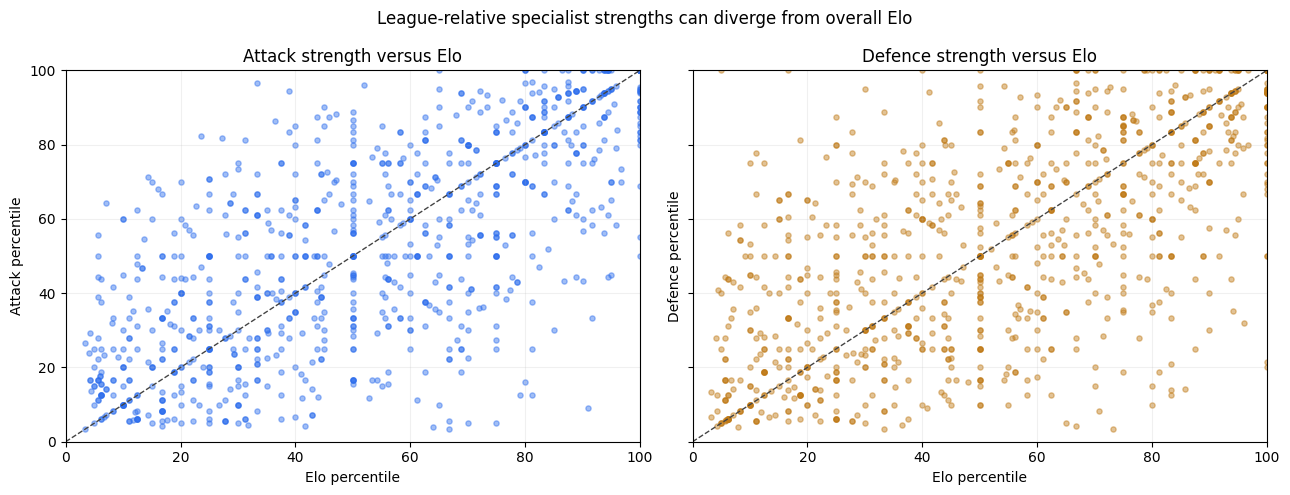

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
eligible = current[current['confidence'] != 'low']
axes[0].scatter(eligible['elo_percentile'], eligible['attack_percentile'], s=14, alpha=.45, color='#2f6fed')
axes[1].scatter(eligible['elo_percentile'], eligible['defence_percentile'], s=14, alpha=.45, color='#c07a17')
for ax, title, ylabel in [
    (axes[0], 'Attack strength versus Elo', 'Attack percentile'),
    (axes[1], 'Defence strength versus Elo', 'Defence percentile'),
]:
    ax.plot([0, 100], [0, 100], color='#444', linewidth=1, linestyle='--')
    ax.set(title=title, xlabel='Elo percentile', ylabel=ylabel, xlim=(0, 100), ylim=(0, 100))
    ax.grid(alpha=.18)
fig.suptitle('League-relative specialist strengths can diverge from overall Elo')
fig.tight_layout()
plt.show()

In [6]:
persistent[[
    'league_label', 'team_name', 'attack_leading_seasons',
    'defence_leading_seasons', 'total_leading_seasons'
]].head(20)

,league_label,team_name,attack_leading_seasons,defence_leading_seasons,total_leading_seasons
0,Serbia — Super Liga,FK Crvena Zvezda,7,6,13
1,Germany — Bundesliga,Bayern München,7,4,11
2,Czech-Republic — Czech Liga,Slavia Praha,6,5,11
3,Norway — Eliteserien,Bodo/Glimt,5,5,10
4,Switzerland — Super League,BSC Young Boys,6,3,9
5,Egypt — Premier League,Al Ahly,6,3,9
6,Lithuania — A Lyga,FK Zalgiris Vilnius,5,4,9
7,Russia — Premier League,Zenit,4,5,9
8,Greece — Super League 1,Olympiakos Piraeus,3,6,9
9,France — Ligue 1,Paris Saint Germain,6,2,8


### Existing walk-forward calibration evidence

In [7]:
validation.assign(
    average_predicted=lambda d: d['average_predicted'].map('{:.1%}'.format),
    actual_hit_rate=lambda d: d['actual_hit_rate'].map('{:.1%}'.format),
    calibration_gap=lambda d: d['calibration_gap'].map('{:+.1%}'.format),
)

,model,predictions,brier_score,average_predicted,actual_hit_rate,calibration_gap
0,bayesian,8452,0.1779,78.5%,76.4%,+2.1%
1,dixon_coles,15128,0.1789,76.9%,76.1%,+0.8%
2,mismatch,2999,0.1524,80.1%,80.8%,-0.7%
3,poisson,6140,0.1861,76.1%,74.9%,+1.3%


## Takeaways

1. Use attack and defence as separate match-up features. Elo is still useful for overall team quality, but it can hide teams that are strong on one side of the ball and weak on the other.
2. Read the index multiplicatively: 120 means roughly 20% stronger than the current league reference on that unit after model adjustment; percentiles are better for quick within-league comparison.
3. Filter or down-weight `low` confidence teams. Their effective history is below six matches after time decay.
4. For SportyBet, convert the two teams' ratings into fixture probabilities, calibrate those probabilities out of sample, and compare them with the bookmaker's implied probability after removing margin. A ranking alone is not a wager.
5. Repair/rebuild the transformed fact before making it the model source. It currently represents only 69.6% of raw completed fixtures.
